# Harmonischer Oszillator

In [1]:
using QuantumOptics, Plots

# task 1: Lösung im Fockraum
Hilbert Space and Operators: Set up a QoJulia based Jupyter notebook and define the corresponding Hilbert
space and corresponding ladder and quadrature operators as well as the Hamiltonian for a single radiation mode.

In [3]:
n = 10; #anzahl der eigenenergien (Photonen) im Fockraum (wegen Vakuumzustand ist dim(H)=11)
basis_Fock = FockBasis(n);

a = destroy(basis_Fock); #absteiger
a⁺ = dagger(a); #aufseiger

N = a⁺*a; #besetzungszahl operator

ħ = 1; ω = 1; m=2;

In [4]:
H = (N+one(basis_Fock)/2)*ħ*ω; #hamiltonian

In [5]:
X = 0.5*(a+a⁺)/√ω; P = 1im*(a⁺-a)*√ω; #quadraturoperatoren bzw Qx, Qy

# task 2
Quantum States: Introduce photon number eigenstates and coherent states. Calculate their expectation values
of the electric field, photon number, energy and the corresponding uncertainties (use the provided notebook as
guideline)

## Photon number eigenstates

In [7]:
ψᵢ = fockstate(basis_Fock, 2); #Eigenzustände 

In [19]:
#calculate expectation values and uncertainty

qX = expect(X, ψᵢ);
qP = expect(P, ψᵢ);
qN = expect(N, ψᵢ);
qH = expect(H, ψᵢ);

ΔX = sqrt.((expect(X^2, ψᵢ)) - qX.^2);
ΔP = sqrt.((expect(P^2, ψᵢ)) - qP.^2);
ΔN = sqrt.((expect(N^2, ψᵢ)) - qN.^2);
ΔH = sqrt.((expect(H^2, ψᵢ)) - qH.^2);

z=[qX, qP, qN, qH, ΔX, ΔP, ΔN, ΔH]

for i in z
    print(" $(i)\n")
end


 0.0 + 0.0im
 0.0 + 0.0im
 2.0000000000000004 + 0.0im
 2.5000000000000004 + 0.0im
 1.118033988749895 + 0.0im
 2.23606797749979 + 0.0im
 0.0 + 0.0im
 0.0 + 0.0im


## Coherent states

In [20]:
ψc(a) = coherentstate(basis_Fock, a); #Definiert funktion die coherente Zustände erzeugt und als argument eine komplexe Zahl alpha nimmt
α = 2; 

ψₐ = ψc(α);

In [21]:
#calculate expectation values and uncertainty

qXₐ = expect(X, ψₐ);
qPₐ = expect(P, ψₐ);
qNₐ = expect(N, ψₐ);
qHₐ = expect(H, ψₐ);

ΔXₐ = sqrt.((expect(X^2, ψₐ)) - qXₐ.^2);
ΔPₐ = sqrt.((expect(P^2, ψₐ)) - qPₐ.^2);
ΔNₐ = sqrt.((expect(N^2, ψₐ)) - qNₐ.^2);
ΔHₐ = sqrt.((expect(H^2, ψₐ)) - qHₐ.^2);

z=[qXₐ, qPₐ, qNₐ, qHₐ, ΔXₐ, ΔPₐ, ΔNₐ, ΔHₐ]

for i in z
    print(" $(i)\n")
end


 1.9837355144061328 + 0.0im
 0.0 - 2.0816681711721685e-17im
 3.967471028812265 + 0.0im
 4.466051145752009 + 0.0im
 0.49044653319573595 + 0.0im
 1.0221509301308036 + 0.0im
 1.9709971366138173 + 0.0im
 1.9740325042445035 + 0.0im


# task 3
Graphical Demonstrations: Plot typical photon number distributions for some examples (check the validity
of the chosen cut-off) . Generate density (heatmap) plots of the Q-functions for coherent and photon number
states.

# Plot photon number distribution

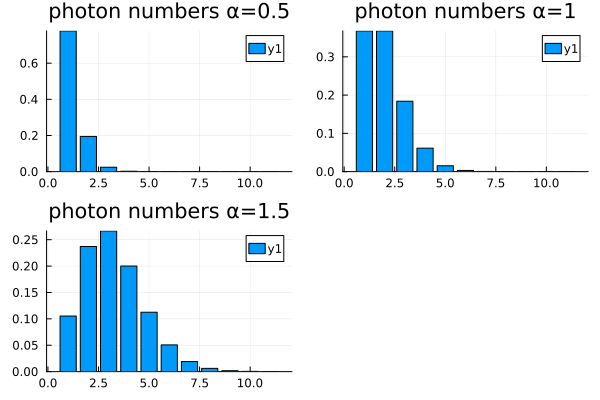

In [22]:
pₙ = abs2.(ψc(0.5).data); p0 = bar(pₙ, title="photon numbers α=0.5"); #Wahrscheinlichkeit im Zustand ψc(0.5) genau n photonen zu finden
pₙ = abs2.(ψc(1).data);   p1 = bar(pₙ, title="photon numbers α=1");
pₙ = abs2.(ψc(1.5).data); p15 = bar(pₙ, title="photon numbers α=1.5");

plot(p0, p1, p15)

# density plot of Q-functions for coherent and photon number states

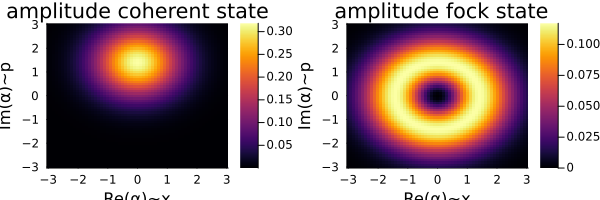

In [23]:
points = -3:0.1:3;

Qf = qfunc(ψc(1), points, points);
plot1 = heatmap(points, points, Qf, xlabel = "Re(α)~x", ylabel = "Im(α)~p", title = "amplitude coherent state");

Qn = qfunc(fockstate(basis_Fock, 1), points, points);
plot2 = heatmap(points, points, Qn, xlabel = "Re(α)~x", ylabel = "Im(α)~p", title = " amplitude fock state");

plot(plot1, plot2, size=(600,200))

# task 4
 Dynamics: Solve for the time-evolution of the corresponding Schr¨odinger equation for a given coherent state
and plot the time dependent expectation values of the field amplitude.

## time evolution of coherent state with α = 1

In [27]:
t = 0:0.1:2*π/ω;

t₁, ψc_t = timeevolution.schroedinger(t, ψc(1), H);

# animated heatplot

[ Info: Saved animation to C:\Users\PCUser\Desktop\Bachelor TPH\Quantenoptik_Numerisch\timeevolution coherent state a=1.gif


Plots.AnimatedGif("C:\\Users\\PCUser\\Desktop\\Bachelor TPH\\Quantenoptik_Numerisch\\timeevolution coherent state a=1.gif")
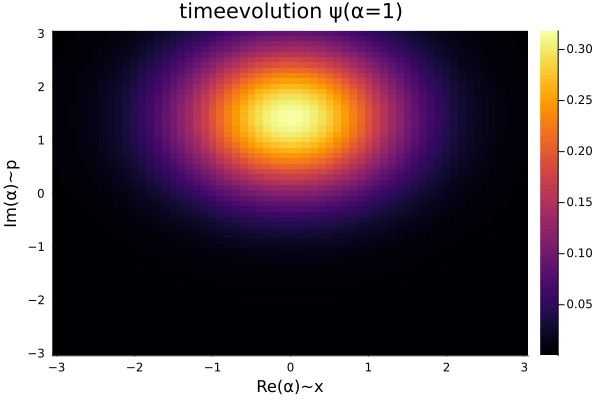

In [28]:
animation=@animate for ψ = ψc_t
    Qf = qfunc(ψ, points, points);
    heatmap(points, points, Qf, xlabel="Re(α)~x", ylabel="Im(α)~p", title="timeevolution ψ(α=1)");
end

gif(animation, "timeevolution coherent state a=1.gif", fps=12)

## time dependent expectation values of the field amplitude.

In [29]:
at = [expect(a, ψc_t[i]) for i in 1:length(t)];

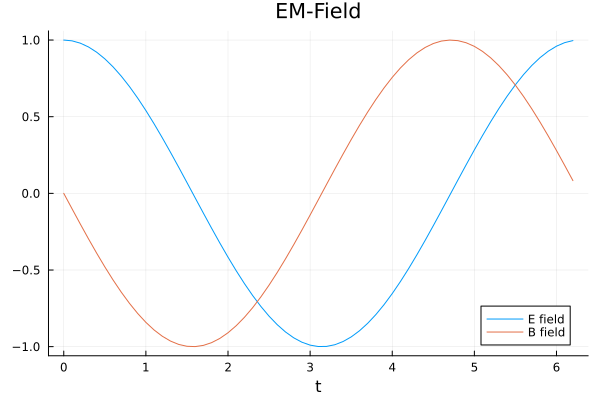

In [30]:
plot(t, real.(at), xlabel="t", label="E field"); plot!(t, imag.(at), label="B field", title="EM-Field")

# task 5
Coherent State Generation: Add a driving term to the Hamiltonian : Hd = η ∗ (a + a†) for a suitable real
parameter η and study the time evolution starting from vacuum.

Plot the expectation values of average photon number and field as function of time.

Plot the photon number distribution at some chosen times and check the validity of the chose cut-off.

Plot the Q-function and compare its shape to the vacuum state Q-function.

# coherent state generation

In [31]:
η = 1.5;
Hₑₜₐ = η*(a + dagger(a));
Hd = H + Hₑₜₐ;

ψᵥ = fockstate(basis_Fock, 0); #vacuum state

t1, ψvtd = timeevolution.schroedinger(t, ψᵥ, Hd);
t2, ψvt = timeevolution.schroedinger(t, ψᵥ, H);

# compare Q functions for vacuum state in timeevolution of driven hamiltonian (generates coherent state) vs. Q function of non driven vacuum state (focstate for 0 photons)

[ Info: Saved animation to C:\Users\PCUser\Desktop\Bachelor TPH\Quantenoptik_Numerisch\timeevolution vacuum state for hamiltonian with driving factor.gif


Plots.AnimatedGif("C:\\Users\\PCUser\\Desktop\\Bachelor TPH\\Quantenoptik_Numerisch\\timeevolution vacuum state for hamiltonian with driving factor.gif")
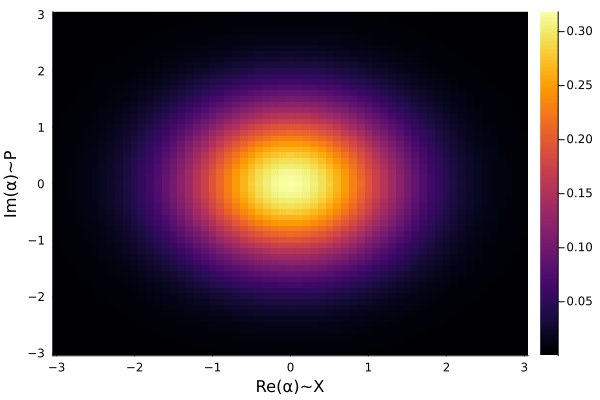

In [45]:
animation2=@animate for ψ = ψvtd
    Q = qfunc(ψ, points, points);
    heatmap(points, points, Q, xlabel="Re(α)~X", ylabel="Im(α)~P");
end

gif(animation2, "timeevolution vacuum state for hamiltonian with driving factor.gif", fps=12)

[ Info: Saved animation to C:\Users\PCUser\Desktop\Bachelor TPH\Quantenoptik_Numerisch\timeevolution vacuum state for hamiltonian without drive.gif


Plots.AnimatedGif("C:\\Users\\PCUser\\Desktop\\Bachelor TPH\\Quantenoptik_Numerisch\\timeevolution vacuum state for hamiltonian without drive.gif")
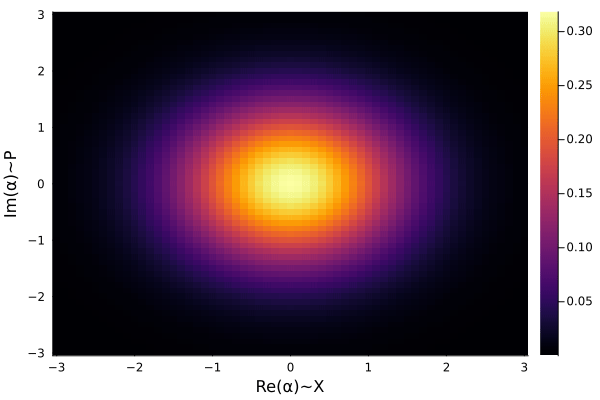

In [46]:
animation3=@animate for ψ = ψvt
    Qv = qfunc(ψ, points, points);
    heatmap(points, points, Qv, xlabel="Re(α)~X", ylabel="Im(α)~P");
end

gif(animation3, "timeevolution vacuum state for hamiltonian without drive.gif", fps=12)

# Plot the expectation values of average photon number and field as function of time (auch falscher plot, sollte auch bewegt im kreis sein)

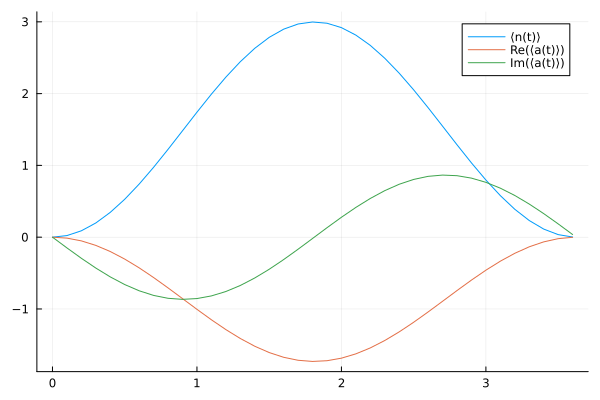

In [47]:
n_t = [expect(N, ψvtd[i]) for i in 1:length(t1)];

a_t = [expect(a, ψvtd[i]) for i in 1:length(t1)];

plot(t1, real.(n_t), label="⟨n(t)⟩") 

plot!(t1, real.(a_t), label="Re(⟨a(t)⟩)")
plot!(t1, imag.(a_t), label="Im(⟨a(t)⟩)")

# Plot the photon number distribution at some chosen times

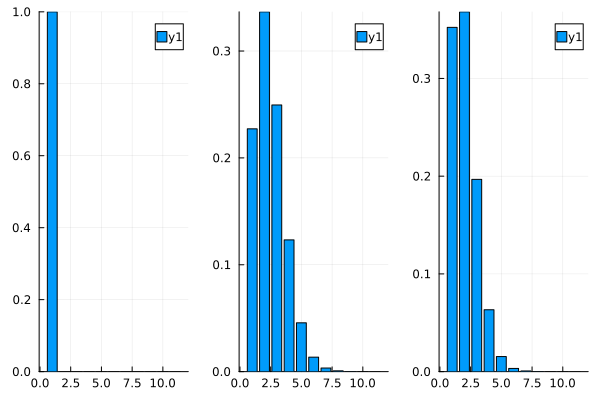

In [53]:
p0 = bar(abs2.(ψvtd[1].data));
p1 = bar(abs2.(ψvtd[10].data));
p3 = bar(abs2.(ψvtd[30].data));

plot(p0, p1, p3, layout=(1,3))


# task 6 Squeezed states: S=exp(µ ∗ (a†)²-µ ∗a²)
Discuss the corresponding expectation values and variances and plot their Q-functions. Depict the photon
number distributions of squeezed vacuum states.

In [96]:
µ=1;
S_μ(μ) = exp(-(µ*dense(a)^2-µ'*dense(a⁺)^2)/2);
ψ_sq(μ, α) = S_μ(μ)*coherentstate(basis_Fock, α);

# squeezed Vacuum

In [97]:
α=0;

ψa = ψ_sq(μ, α);

qX_sqv = expect(X, ψa);
qP_sqv = expect(P, ψa);
qN_sqv = expect(N, ψa);
qH_sqv = expect(H, ψa);

ΔX_sqv = sqrt.((expect(X^2, ψa)) - qX_sqv.^2);
ΔP_sqv = sqrt.((expect(P^2, ψa)) - qP_sqv.^2);
ΔN_sqv = sqrt.((expect(N^2, ψa)) - qN_sqv.^2);
ΔH_sqv = sqrt.((expect(H^2, ψa)) - qH_sqv.^2);

list=[qX_sqv, qP_sqv, qN_sqv, qH_sqv, ΔX_sqv, ΔP_sqv, ΔN_sqv, ΔH_sqv];

for i in list
    print("$(i)\n")
end

0.0 + 0.0im
0.0 + 0.0im
1.327561615611352 + 0.0im
1.8275616156113523 + 0.0im
1.2744402570122002 + 0.0im
0.47339198668964255 + 0.0im
2.3015603829095856 + 0.0im
2.3015603829095856 + 0.0im


# general squeeze

In [98]:
α=1.5; 
ψb = ψ_sq(μ, α);

qX_sqg = expect(X, ψb);
qP_sqg = expect(P, ψb);
qN_sqg = expect(N, ψb);
qH_sqg = expect(H, ψb);

ΔX_sqg = sqrt.((expect(X^2, ψb)) - qX_sqg.^2);
ΔP_sqg = sqrt.((expect(P^2, ψb)) - qP_sqg.^2);
ΔN_sqg = sqrt.((expect(N^2, ψb)) - qN_sqg.^2);
ΔH_sqg = sqrt.((expect(H^2, ψb)) - qH_sqg.^2);

list_g=[qX_sqg, qP_sqg, qN_sqg, qH_sqg, ΔX_sqg, ΔP_sqg, ΔN_sqg, ΔH_sqg];

for k in list_g
    print("$(k)\n")
end

0.885346140276014 + 0.0im
0.0 + 0.0im
6.55930143765037 + 0.0im
7.059289326736258 + 0.0im
1.096295471548757 + 0.0im
4.065168657465107 + 0.0im
2.4716481468858116 + 0.0im
2.471681511762213 + 0.0im


# q functions

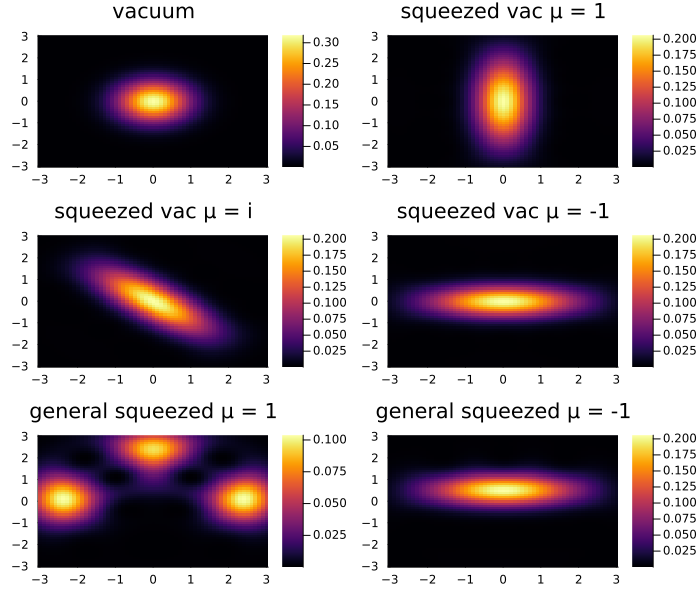

In [105]:
qf_vac = qfunc(ψ_sq(0, 0), 1.5*points, 1.5*points);
qf_vaci = qfunc(ψ_sq(1im, 0), 1.5*points, 1.5*points);
qf_vac1 = qfunc(ψ_sq(1, 0), 1.5*points, 1.5*points);
qf_vacm1 = qfunc(ψ_sq(-1, 0), 1.5*points, 1.5*points);
qf_gen1 = qfunc(ψ_sq(1, 1.5), 1.5*points, 1.5*points);
qf_genm1 = qfunc(ψ_sq(-1, 1.5), 1.5*points, 1.5*points);

p_vac = heatmap(points, points, qf_vac, title="vacuum", size=(400,300));
p_vac1 = heatmap(points, points, qf_vac1, title="squeezed vac μ = 1", size=(400,300));
p_vaci = heatmap(points, points, qf_vaci, title="squeezed vac μ = i", size=(400,300));
p_vacm1 = heatmap(points, points, qf_vacm1, title="squeezed vac μ = -1", size=(400,300));
p_gen1 = heatmap(points, points, qf_gen1, title="general squeezed μ = 1", size=(400,300));
p_genm1 = heatmap(points, points, qf_genm1, title="general squeezed μ = -1", size=(400,300));

plot(p_vac, p_vac1, p_vaci, p_vacm1, p_gen1, p_genm1, size=(700,600), layout=(3,2))

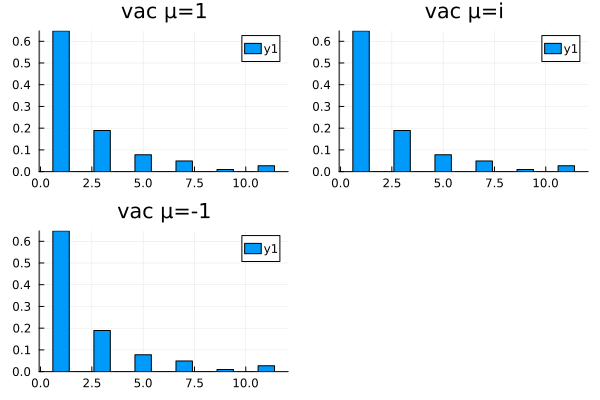

In [109]:
#photonnumber distribution

#vacuum squeezed
p_vac1 = bar(abs2.(ψ_sq(1, 0).data), title="vac μ=1");
p_vaci = bar(abs2.(ψ_sq(1im, 0).data), title="vac μ=i");
p_vacm1 = bar(abs2.(ψ_sq(-1, 0).data), title="vac μ=-1");

plot(p_vac1, p_vaci, p_vacm1)